# When Time Runs Out, Who Uses AI as an Answer Key?

## Idea

We think running out of time is a big reason students lean on AI. The survey asked students what they do when they're stuck on a homework problem and **don't have enough time** to finish: keep going without AI, ask AI for a hint, or ask AI for the complete solution. It also asked how often they find themselves **relying on AI more after they procrastinate**.

We expect that students who rely on AI more after procrastinating will be more likely to ask AI for the **full solution** when time runs out, using it as an answer key instead of a tutor.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.mosaicplot import mosaic
from scipy.stats import chi2_contingency, chi2

df = pd.read_csv("../../data/uncleaned_data.csv")

# The answers use a curly apostrophe (’). Swap it for a normal one (') so we can type the answers exactly.
df = df.replace("’", "'", regex=True)

## Data Cleaning

Because some questions had answer choices that were too small on their own, we decided to combine them.

- [CU] "I find myself relying on AI more after I procrastinate" had 5 options (Never | Rarely | Sometimes | Often | Always). We combined "Never" with "Rarely" and "Often" with "Always," and left "Sometimes" as is.

- [BU] "When you don't have enough time to finish your assignment before the deadline" also had 5 options (Try on my own | Ask a classmate or TA | Ask AI for a hint | Ask AI for the complete solution | Leave it incomplete). We combined "Try on my own," "Ask a classmate or TA," and "Leave it incomplete" into one "No AI" group, and left "Ask AI for a hint" and "Ask AI for the complete solution" as they are.

In [2]:
# look through the df to find the specific columns in question
procrastinate_col = [c for c in df.columns if "relying on AI more after I procrastinate" in c][0]
no_time_col = [c for c in df.columns if "t have enough time to finish" in c][0]   # "don't have enough time"

# break down the groups like stated in the above markdown cell
procrastinate_groups = {
    "Never": "Never/Rarely",
    "Rarely": "Never/Rarely",
    "Sometimes": "Sometimes",
    "Often": "Often/Always",
    "Always": "Often/Always",
}
no_time_groups = {
    "Trying on my own": "No AI",
    "Seek help from a classmate or TA": "No AI",
    "Leave the problem as incomplete": "No AI",
    "Ask AI for a hint or explanation": "AI hint",
    "Ask AI for the complete solution": "AI full solution",
}

# One row per student with their two grouped answers. Drop students who skipped either question.
data = pd.DataFrame({
    "procrastinate": df[procrastinate_col].map(procrastinate_groups),
    "no_time": df[no_time_col].map(no_time_groups),
}).dropna()

# row and col ordering
col_order = ["Never/Rarely", "Sometimes", "Often/Always"]
tile_order = ["No AI", "AI hint", "AI full solution"]

# create the table that shows the counts and percentages of students
table = pd.crosstab(data["procrastinate"], data["no_time"]).loc[col_order, tile_order]
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(0)



## Build and Plot

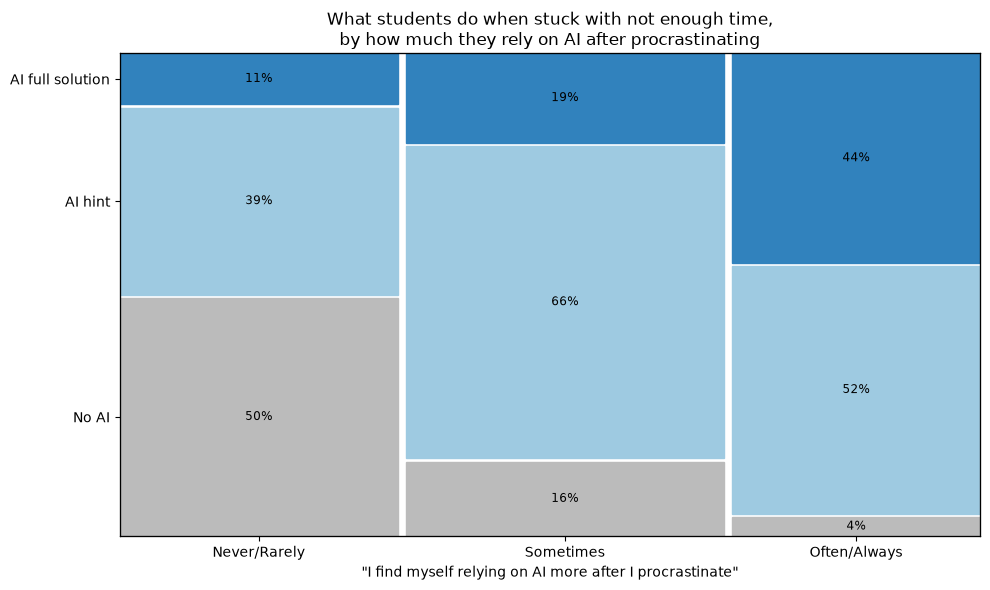

In [3]:
colors = {"No AI": "#BBBBBB", "AI hint": "#9ECAE1", "AI full solution": "#3182BD"}

# mosaic() wants a dictionary of {(column, tile): count}
counts = {}
for c in col_order:
    for t in tile_order:
        counts[(c, t)] = table.loc[c, t]

fig, ax = plt.subplots(figsize=(10, 6))
mosaic(
    counts,
    ax=ax,
    gap=0.01,
    properties=lambda key: {"color": colors[key[1]]},           # color each tile by its answer
    labelizer=lambda key: f"{percent.loc[key[0], key[1]]:.0f}%",  # write the % inside each tile
)
ax.set_xlabel('"I find myself relying on AI more after I procrastinate"')
ax.set_title("What students do when stuck with not enough time,\nby how much they rely on AI after procrastinating")
plt.tight_layout()
plt.show()

## Conclusion

Each column's width represents how many students find themselves relying on AI after they procrastinate. The number of students in never/rarely and often/always are about the same, 28 and 25 respectively, with 32 in sometimes. Each block in a column represents the share of students in that column and how they use AI when out of time. It is clear that as we move from left to right, the students who often/always rely on AI after procrastinating take a bigger share of asking AI for the full solution (11% $\rightarrow$ 19% $\rightarrow$ 44%). What this can tell us is that procrastination goes hand in hand with using AI as an answer key when time runs out.

## Hypothesis: Chi-Squared Test

Are two categorical variables related, or independent? Does what a student does when out of time depend on their procrastination group?

**$H_0$:** procrastination group has nothing to do with what students do when out of time.  
**$H_1$:** the two are related

Because the variables are categorical we will be using a chi-square test with an $\alpha$ value of 0.05.

In [6]:
# contingency table (observed frequencies)
# rows: procrastination groups col: use of AI
observed = pd.crosstab(data["procrastinate"], data["no_time"]).loc[col_order, tile_order]
print("Observed Frequencies:")
print(observed)

# chi test
chi_stat, p_value, degrees_freedom, expected_freq = chi2_contingency(observed)

# expected frequencies
expected = pd.DataFrame(expected_freq, index=observed.index, columns=observed.columns)
print("\nExpected Frequencies:")
print(expected.round(1))

# results
print(f"\nChi-Square Statistic (X^2): {chi_stat:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {degrees_freedom}")
print("Significance Level: a = 0.05")

# critical value
critical_value = chi2.ppf(0.95, degrees_freedom)
print(f"Critical Value at a=0.05: {critical_value:.4f}")

Observed Frequencies:
no_time        No AI  AI hint  AI full solution
procrastinate                                  
Never/Rarely      14       11                 3
Sometimes          5       21                 6
Often/Always       1       13                11

Expected Frequencies:
no_time        No AI  AI hint  AI full solution
procrastinate                                  
Never/Rarely     6.6     14.8               6.6
Sometimes        7.5     16.9               7.5
Often/Always     5.9     13.2               5.9

Chi-Square Statistic (X^2): 21.9205
P-value: 0.0002
Degrees of Freedom: 4
Significance Level: a = 0.05
Critical Value at a=0.05: 9.4877


**Result:** $\chi^2$ = 21.92 is greater than the critical value of 9.49 (df = 4, $\alpha$ = 0.05), so we reject $H_0$. Students who rely on AI more after procrastinating are significantly more likely to ask AI for the full solution when they run out of time.